<a href="https://colab.research.google.com/github/parvej-mosaraf/IRE-416-Computer-Vision-Sessional/blob/main/Assignment/Assignment%202/CV_Assignment_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Assignment 2
```
Md. Parvej Mosaraf
Group: 02 ID: 2101024
Session: 2021-2022
Department of Internet of Things & Robotics Engineering (IRE)
University of Frontier Technology, Bangladesh
```



In [ ]:
import urllib.request

# Download the cracker_box.jpg image
image_url = 'https://github.com/parvej-mosaraf/IRE-416-Computer-Vision-Sessional/blob/main/Assignment/Assignment%202/cracker_box.jpg?raw=true'
urllib.request.urlretrieve(image_url, 'cracker_box.jpg')
print('Downloaded cracker_box.jpg successfully.')

Downloaded cracker_box.jpg successfully.


### Problem 1

Edge pixels: 7967
Total pixels: 307200
Edge percentage: 2.593424479166667


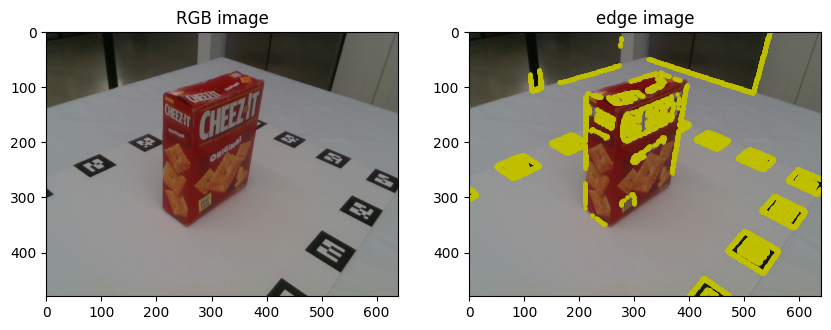

In [ ]:
"""
CS 4391 Homework 2 Programming
Implement the edge_detection() function in this python script
Edge Detection
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt


#TODO: implement this function
# input: im is an RGB image with shape [height, width, 3]
# output: edge_mask with shape [height, width] with valuse 0 and 1, where 1s indicate edge pixels of the input image
# You can use opencv functions and numpy functions
def edge_detection(im):

    # Step 0: Convert BGR to grayscale
    gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)

    # Step 1: Compute image gradient using 5x5 Sobel filters
    grad_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=5, scale=1/575)
    grad_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=5, scale=1/575)

    # Step 2: Compute gradient magnitude
    gradient_magnitude = np.sqrt(grad_x**2 + grad_y**2)

    # Step 3: Apply threshold = 5
    edge_mask = (gradient_magnitude > 5).astype(np.uint8)

    print("Edge pixels:", np.sum(edge_mask))
    print("Total pixels:", edge_mask.size)
    print("Edge percentage:", np.mean(edge_mask) * 100)

    return edge_mask


# main function
if __name__ == '__main__':

    # read the image in data
    # rgb image
    rgb_filename = 'cracker_box.jpg'
    im = cv2.imread(rgb_filename)

    # your implementation of the edge detector
    edge_mask = edge_detection(im)

    # visualization for your debugging
    fig = plt.figure(figsize=(10, 5))

    # show RGB image
    ax = fig.add_subplot(1, 2, 1)
    plt.imshow(im[:, :, (2, 1, 0)])
    ax.set_title('RGB image')

    # show your edge image
    ax = fig.add_subplot(1, 2, 2)
    plt.imshow(im[:, :, (2, 1, 0)])
    index = np.where(edge_mask > 0)
    plt.scatter(x=index[1], y=index[0], c='y', s=5)
    ax.set_title('edge image')

    plt.show()

### Problem 2

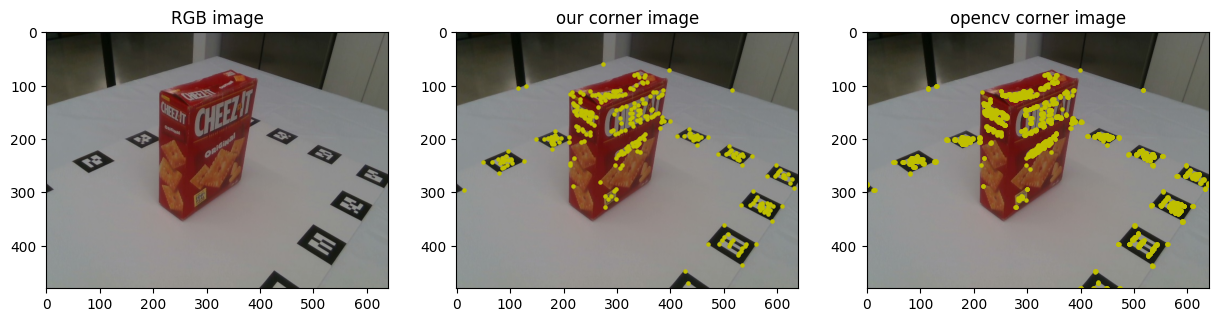

In [ ]:
"""
CS 4391 Homework 2 Programming
Implement the harris_corner() function and the non_maximum_suppression() function in this python script
Harris corner detector
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt


#TODO: implement this function
# input: R is a Harris corner score matrix with shape [height, width]
# output: mask with shape [height, width] with valuse 0 and 1, where 1s indicate corners of the input image
# idea: for each pixel, check its 8 neighborhoods in the image. If the pixel is the maximum compared to these
# 8 neighborhoods, mark it as a corner with value 1. Otherwise, mark it as non-corner with value 0
def non_maximum_suppression(R):
    height, width = R.shape
    mask = np.zeros((height, width), dtype=np.uint8)

    for i in range(1, height - 1):
        for j in range(1, width - 1):
            if R[i, j] > 0:
                neighborhood = R[i-1:i+2, j-1:j+2]
                if R[i, j] == np.max(neighborhood):
                    mask[i, j] = 1
    return mask


#TODO: implement this function
# input: im is an RGB image with shape [height, width, 3]
# output: corner_mask with shape [height, width] with valuse 0 and 1, where 1s indicate corners of the input image
# You can use opencv functions and numpy functions
def harris_corner(im):

    # step 0: convert RGB to gray-scale image
    gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    gray = np.float32(gray)

    # step 1: compute image gradient using Sobel filters
    Ix = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    Iy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

    # step 2: compute products of derivatives at every pixels
    Ix2 = Ix * Ix
    Iy2 = Iy * Iy
    Ixy = Ix * Iy

    # step 3: compute the sums of products of derivatives at each pixel using Gaussian filter from OpenCV
    # Kernel size 5 with sigma=1 is standard for Harris detector smoothing
    Sx2 = cv2.GaussianBlur(Ix2, (5, 5), 1)
    Sy2 = cv2.GaussianBlur(Iy2, (5, 5), 1)
    Sxy = cv2.GaussianBlur(Ixy, (5, 5), 1)

    # step 4: compute determinant and trace of the M matrix
    det_M = (Sx2 * Sy2) - (Sxy ** 2)
    trace_M = Sx2 + Sy2

    # step 5: compute R scores with k = 0.05
    k = 0.05
    R = det_M - k * (trace_M ** 2)

    # step 6: thresholding
    threshold = 0.01 * R.max()
    R[R < threshold] = 0

    # step 7: non-maximum suppression
    corner_mask = non_maximum_suppression(R)

    return corner_mask


# main function
if __name__ == '__main__':

    # read the image in data
    # rgb image
    rgb_filename = 'cracker_box.jpg'
    im = cv2.imread(rgb_filename)

    # your implementation of the harris corner detector
    corner_mask = harris_corner(im)

    # opencv harris corner
    img = im.copy()
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = np.float32(gray)
    dst = cv2.cornerHarris(gray, 2, 3, 0.04)
    opencv_mask = dst > 0.01 * dst.max()

    # visualization for your debugging
    fig = plt.figure(figsize=(15, 5))

    # show RGB image
    ax = fig.add_subplot(1, 3, 1)
    plt.imshow(im[:, :, (2, 1, 0)])
    ax.set_title('RGB image')

    # show our corner image
    ax = fig.add_subplot(1, 3, 2)
    plt.imshow(im[:, :, (2, 1, 0)])
    index = np.where(corner_mask > 0)
    plt.scatter(x=index[1], y=index[0], c='y', s=5)
    ax.set_title('our corner image')

    # show opencv corner image
    ax = fig.add_subplot(1, 3, 3)
    plt.imshow(im[:, :, (2, 1, 0)])
    index = np.where(opencv_mask > 0)
    plt.scatter(x=index[1], y=index[0], c='y', s=5)
    ax.set_title('opencv corner image')

    plt.show()